# Evaluacion de Regresión

![Logo Itq](img/ITQ.png)

**Nombre:** Angelica Paredes

**Fecha:** 19/11/2026

**Link del repositorio:** <a href="https://github.com/AngelicaPar/FundamentosMachineLearning26-27/blob/main/Programa10.EvaluacionRegresion.ipynb">Link Repositorio</a>

**Evaluación de regresión:** Es el proceso de medir qué tan precisas son las predicciones numéricas continuas de un modelo comparándolas con los valores reales. Permite verificar si el algoritmo aprendió bien las relaciones entre variables o si presenta errores.

**sqrt:** Es la abreviatura de raíz cuadrada.

**pprint:** Es un módulo integrado en Python da formato legible y organizado a estructuras de datos complejas.

**cross_validate:** Es para evaluar el rendimiento real de un modelo predictivo y comprobar qué tan bien generaliza ante datos nuevos que no ha visto.

**make_scorer:** Es una función de la librería Scikit-learn que convierte métricas personalizadas o funciones de pérdida en un objeto evaluador compatible con sus herramientas de validación.

**mean_absolute_error:** Mide el promedio de las diferencias absolutas entre los valores reales y las predicciones de un modelo.

**clone:** Es para crear una copia exacta e independiente de un archivo.

**make_pipeline:** Se utiliza para encadenar múltiples pasos de procesamiento de datos y un modelo de aprendizaje automático en un solo objeto.

In [57]:
import numpy as np
import pandas as pd
from math import sqrt
from pprint import pprint
from sklearn import datasets
#from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_validate
from sklearn.model_selection import KFold
from sklearn.metrics import make_scorer
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_absolute_percentage_error
import matplotlib.pyplot as plt
from sklearn import preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone
from sklearn.pipeline import Pipeline ,make_pipeline

In [58]:
# Cargar y explorar los datos
datos = datasets.load_diabetes(as_frame = True)
#pprint(datos)
#print(np.shape(datos.data))
df = datos.frame
display(df.head())
print("Dimensiones", df.shape)

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


Dimensiones (442, 11)


In [59]:
# Extraer la matriz de datos "X" y la variable target "y"
X = datos.data
y = datos.target

In [60]:
# Partición EXTERNA: hold-out split 80% train - 20% test.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20, random_state = 42)
print("Datos de entrenamiento: " , X_train.shape)
print("Datos de test: ", X_test.shape)

Datos de entrenamiento:  (353, 10)
Datos de test:  (89, 10)


In [61]:
# Estandarización de los datos de entrenamiento y test
standarizer = preprocessing.StandardScaler()

In [62]:
# Métricas de evaluación.
metricas = {
  'MAE': 'neg_mean_absolute_error',
  'RMSE': make_scorer(lambda y, y_pred:
                      sqrt(mean_squared_error(y, y_pred)),
                      greater_is_better=False),
  'MAPE': make_scorer(lambda y, y_pred:
                      np.mean(np.abs((y - y_pred) / y)) * 100,
                      greater_is_better=False)}

In [63]:
# Definimos un algoritmo SVM de regresión
alg = Pipeline([
    ("standarizer", standarizer),
    ("regresion", SVR(C=10, gamma = "scale", kernel="rbf"))
      ])

In [64]:
# Validación y evaluación del modelo.
# en "cv = KFold(n_splits=5)" se hace un cross-validation INTERNO!! 
results = cross_validate(alg, X_train, y_train, cv = KFold(n_splits=5, shuffle=True, random_state=42), scoring = metricas)


In [65]:
# Presentación de los resultados de la evaluación.
pprint(results)

{'fit_time': array([0.05421281, 0.01543093, 0.01032281, 0.0082159 , 0.00812793]),
 'score_time': array([0.01827598, 0.00645423, 0.0052352 , 0.00485253, 0.00471711]),
 'test_MAE': array([-48.26285616, -51.99094138, -42.19909846, -45.73437715,
       -50.39789838]),
 'test_MAPE': array([-32.83110657, -45.90028442, -37.74947192, -43.12401136,
       -44.16570536]),
 'test_RMSE': array([-57.68310314, -60.27338482, -51.94585761, -55.51382769,
       -63.98279561])}


In [66]:
# Una vez hemos optimizado los hiperparámetros en el conjunto de validación, entrenamos un nuevo modelo que contenga
# todos los datos de entrenamiento (es decir, train + validation) para evaluar el test
# model = SVR(C=10, gamma='scale', kernel='rbf')
model = clone(alg)
model = model.fit(X_train, y_train)

In [67]:
# Extraemos el error absoluto promedio (MAE) del conjunto de test
y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)

print('Test results (MAE): ', mae)
print(" Test results (RMSE): " , round(sqrt(mean_squared_error(y_test, y_pred)),3))
print("Test results (MAPE): ", round(mean_absolute_percentage_error(y_test, y_pred)*100,3))   

Test results (MAE):  41.31967129510745
 Test results (RMSE):  51.792
Test results (MAPE):  36.339


In [68]:
# También podemos extraer las predicciones para cuánto difieren los valores predichos de los reales
print('Predicciones:   ', np.round(y_pred[:10], 1))
print('Valores reales: ', y_test[:10])

Predicciones:    [149.  172.2 152.9 212.3 110.1 122.3 227.3 191.8 106.7 103.9]
Valores reales:  287    219.0
211     70.0
72     202.0
321    230.0
73     111.0
418     84.0
367    242.0
354    272.0
281     94.0
148     96.0
Name: target, dtype: float64


In [69]:
# Grafica de realidad -vs- prediccion.
def grafica_real_vs_pred(y_true, y_pred, metricas, algoritmo):
    fig, ax = plt.subplots()
    ax.scatter(y_true, y_pred, edgecolors=(0, 0, 0))
    ax.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], 'k--', lw=4)
    ax.set_xlabel('Valor real de la clase')
    ax.set_ylabel('Predicción')
    plt.show()

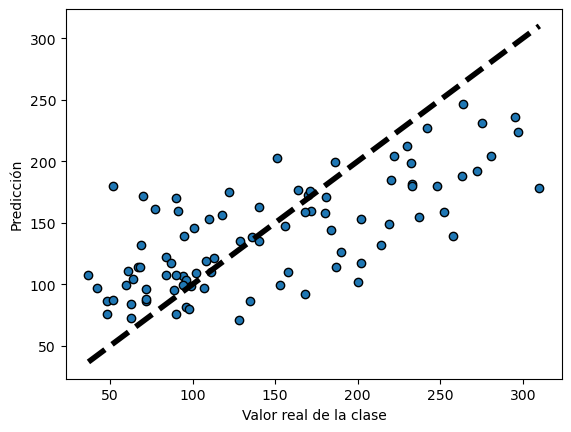

In [70]:
grafica_real_vs_pred(y_test, y_pred, metricas, model)